# Part I: Bag of Words

In [1]:
#adapted from:
#https://github.com/sahilee26/IMDB-Movie-Reviews-Sentiment-Analysis/blob/master/Bag-of-words-random-forest.ipynb
#https://github.com/shiaoligreen/practical-data-science/tree/master/Bag%20of%20Words%20Meets%20Bags%20of%20Popcorn
#https://github.com/amueller/word_cloud

# Load packages
import pandas as pd  
from bs4 import BeautifulSoup  
import re
import nltk
from nltk.corpus import stopwords as nltkstopwords
import nltk.data
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np
import logging
from sklearn.ensemble import RandomForestClassifier
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
import graphviz
from sklearn.tree import export_graphviz
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
lemmatizer = WordNetLemmatizer()
import time

In [2]:
# Load data
train = pd.read_csv("data/labeledTrainData.tsv", 
                    header=0, delimiter="\t", 
                    quoting=3)
# Outputs a pandas dataframe

test = pd.read_csv("data/testData.tsv", 
                   header=0, delimiter="\t",
                   quoting=3 )

unlabeled_train = pd.read_csv("data/unlabeledTrainData.tsv", header=0, 
                              delimiter="\t", quoting=3 )

# Split data to test preprocessing and modeling techniques
X_train, X_test, y_train, y_test = train_test_split(train.drop(columns=['sentiment']), 
                                                    train.sentiment, test_size=0.2)
# One portion to train, Another to evaluate the model
# X is model/input value, Y is the answers --- Given X predict Y

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

In [3]:
def review_to_words(review, string = True, remove_stopwords=True):
    '''
    Function to convert a document to a sequence of words, 
    optionally removing stop words.  
    Returns a list or string of words.
    '''
    # 1. Remove HTML
    review_text = BeautifulSoup(review).get_text()
    
    # 2. Remove non-letters
    review_text = re.sub("[^a-zA-Z]"," ", review_text)
    
    # 3. Convert to lower case FIRST
    review_text_cleaned = review_text.lower().split()
    
    # 5. Lemmatize the tokens
    words = [lemmatizer.lemmatize(word) for word in review_text_cleaned]

    #words = review_text_cleaned
    
    # 6. Remove stop words
    if remove_stopwords:
        stops = set(nltkstopwords.words("english"))
        words = [w for w in words if w not in stops]
        
    if string:
        return " ".join(words)
    else:
        return words

In [4]:
#print(type(X_train)) # <class 'pandas.core.frame.DataFrame'>
#print(type(y_train)) # <class 'pandas.core.series.Series'>
#print(X_train) # Table with the index, id and review
#print("") # Prints nothing; What did you expect?
#print(X_train.loc[0]) # Prints the 1st element from the table in dictionary-esque format
#print("") # Prints nothing; What did you expect?
print(y_train.loc[::-1]) # Prints 72-75 in 1-train vector form? Length of output directly correlates to 
#print(y_train.loc[4]) # Prints 1 (an answer in vector form?)
#print(X_train.loc[4]) # Prints the element of the table with index 4
# .iloc finds elements based on index while .loc finds based on the original row number ; reset_index resets the index

21926    0
,17718    1
,9984     0
,13279    0
,13202    1
,        ..
,2342     1
,10596    0
,2397     1
,4492     1
,19795    1
,Name: sentiment, Length: 20000, dtype: int64


In [5]:
# get all the positive review rows from the pandas dataframe
# get every row except when the sentiment for the row is 0
# make a new dataframe from selected rows
# Splits Positive and Negative Reviews
y_train_list = y_train.tolist()
print(type(X_train))
print(X_train)

pos_reviews = []
neg_reviews = []
for idx in range(len(X_train)):
    if y_train_list[idx] == 1:
        pos_reviews.append(X_train.loc[idx]["review"])
    else:
        neg_reviews.append(X_train.loc[idx]["review"])

#print(y_train_list)
#X_train_positive = X_train[i]
#print(X_train_positive)

# get all the negative review rows from the pandas dataframe

print(pos_reviews[0])
print(neg_reviews[0])

<class 'pandas.core.frame.DataFrame'>
,              id                                             review
,0      "1879_10"  "I was too young to remmeber when I first saw ...
,1        "777_7"  "I saw this film at the Chicago Reeling film f...
,2        "283_8"  "\"The Days\" is a typical family drama with a...
,3       "1298_3"  "Sogo Ishii can be a skilled filmmaker under t...
,4       "2068_8"  "1958. The sleepy small Southern town of Clark...
,...          ...                                                ...
,19995  "4581_10"  "A French novelist, disgusted by his wife's so...
,19996  "12278_1"  "When watching this show you are not quite sur...
,19997   "1359_2"  "A good cast is appallingly wasted in this slo...
,19998   "8961_9"  "Bell, Book and Candle was one of the great po...
,19999   "9041_1"  "I kinda liked the film despite it's frenzied ...
,
,[20000 rows x 2 columns]
,"I was too young to remmeber when I first saw this movie. But I saw it for like the second time about 7 y

In [6]:
# Download text datasets, including stop words
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
,[nltk_data]     /users/PZS1154/dukki/nltk_data...
,[nltk_data]   Package stopwords is already up-to-date!


True

In [7]:
from nltk.corpus import stopwords as nltkstopwords
print(nltkstopwords.words('french'))
print(nltkstopwords.words('german'))
print(nltkstopwords.words('english'))
print(nltkstopwords.words.__dir__)

['au', 'aux', 'avec', 'ce', 'ces', 'dans', 'de', 'des', 'du', 'elle', 'en', 'et', 'eux', 'il', 'ils', 'je', 'la', 'le', 'les', 'leur', 'lui', 'ma', 'mais', 'me', 'même', 'mes', 'moi', 'mon', 'ne', 'nos', 'notre', 'nous', 'on', 'ou', 'par', 'pas', 'pour', 'qu', 'que', 'qui', 'sa', 'se', 'ses', 'son', 'sur', 'ta', 'te', 'tes', 'toi', 'ton', 'tu', 'un', 'une', 'vos', 'votre', 'vous', 'c', 'd', 'j', 'l', 'à', 'm', 'n', 's', 't', 'y', 'été', 'étée', 'étées', 'étés', 'étant', 'étante', 'étants', 'étantes', 'suis', 'es', 'est', 'sommes', 'êtes', 'sont', 'serai', 'seras', 'sera', 'serons', 'serez', 'seront', 'serais', 'serait', 'serions', 'seriez', 'seraient', 'étais', 'était', 'étions', 'étiez', 'étaient', 'fus', 'fut', 'fûmes', 'fûtes', 'furent', 'sois', 'soit', 'soyons', 'soyez', 'soient', 'fusse', 'fusses', 'fût', 'fussions', 'fussiez', 'fussent', 'ayant', 'ayante', 'ayantes', 'ayants', 'eu', 'eue', 'eues', 'eus', 'ai', 'as', 'avons', 'avez', 'ont', 'aurai', 'auras', 'aura', 'aurons', 'aur

In [8]:
# Can you select a single review (any random review) from the training data and pass it to review_to_words()?  What is the output?

# your code here
# get a single review from X_train
# print the review
# pass it as an argument to review_to_words()
# print the output

print(review_to_words(neg_reviews[0], string=True, remove_stopwords=True))

sogo ishii skilled filmmaker right condition gojoe tell story warrior monk rival scion genji clan film making ha main hallmark low budget production including blurry fight scene clumsy montage kind might find produced dorama monk benkei informs spiritual teacher destiny lie defeating mysterious spirit guard gojoe bridge night realize decision bring squarely conflict nearly every element society time could earn enlightenment absence ambitiousness however depiction conflict holy worldly artsy flourish photography editing help compensate loose film making style disappointment


In [9]:
sentence = ["I", "did", "not", "like", "the", "movie"]
#expected output: [["I", "did"], ["did", "not"], ["not", "like"], ["like", "the"], ["the", "movie"]]

#Write a function to convert a list of words to a list of bigrams
#def sentence_to_bigrams(sentence: [str]):
#    pass

In [10]:
sentence = ["I", "did", "not", "like", "the", "movie"]

def sentence_to_bigrams(sentence: [str]):
    modified_sentence = BeautifulSoup(sentence).get_text()
    modified_sentence = re.sub("[^a-zA-Z]"," ", modified_sentence)
    words = modified_sentence.lower().split()
        
    bigrams = []
    for idx in range(len(words)-1):
        bigrams.append(words[idx:idx+2])

    return bigrams

print(sentence_to_bigrams(" ".join(sentence)))

[['i', 'did'], ['did', 'not'], ['not', 'like'], ['like', 'the'], ['the', 'movie']]


In [11]:
#Can you modify the function above to add a special START and END token in the function above and then get all bigrams?
#Call it "sentence_to_padded_bigrams"
# What is different about the new output?
# What can it capture that the unpadded version cannot?

In [12]:
sentence = ["I", "did", "not", "like", "the", "movie"]

def sentence_to_padded_bigrams(sentence: [str]):
    modified_sentence = BeautifulSoup(sentence).get_text()
    modified_sentence = re.sub("[^a-zA-Z]"," ", modified_sentence)
    words = ("<START> " + modified_sentence.lower() + " <END>").split()
        
    bigrams = []
    for idx in range(len(words)-1):
        bigrams.append(words[idx:idx+2])

    return bigrams

print(sentence_to_padded_bigrams(" ".join(sentence)))

[['<START>', 'i'], ['i', 'did'], ['did', 'not'], ['not', 'like'], ['like', 'the'], ['the', 'movie'], ['movie', '<END>']]


In [13]:
def review_to_bigrams(review: [str], string = False, remove_stopwords=False):
    '''
    Function to convert a document to a sequence of word bigrams,
    optionally removing stop words.
    Returns a list of bigrams.
    '''
    #E.g., ["I", "liked", "this" ,"movie"] -> ["I liked", "liked_this", "this movie"]
    #your code here
    #     
    # Remove HTML
    review_text = BeautifulSoup(review).get_text()
    # Remove non-letters
    review_text = re.sub("[^a-zA-Z]"," ", review_text)
    # Convert words to lower case and split them
    words = review_text.lower().split()
    
    # Optionally remove stop words (false by default)
    if remove_stopwords:
        stops = set(nltkstopwords.words("english"))
        words = [w for w in words if not w in stops]
        
    bigrams = []
    for i in range(len(words)-1):
        #print(i)
        bigrams.append(words[i] + "_" + words[i+1])

    if string:
        return " ".join(bigrams)

    return bigrams

#print(review_to_bigrams(["I", "liked", "this", "movie"]))
my_bigrams = review_to_bigrams("I liked this movie", string = True)
print(my_bigrams)

i_liked liked_this this_movie


In [14]:
# Get list of reviews
# hint: use a list comprehension to covert all reviews to words, using the X_train object's 'review'
#clean_train_reviews = 
#clean_test_reviews = 

#print(clean_train_reviews[0])

In [15]:
cleaned_training_reviews = [review_to_words(X_train["review"][i]) for i in range(len(X_train))]
cleaned_test_reviews = [review_to_words(X_test["review"][i]) for i in range(len(X_test))]

In [16]:
# Get lists of reviews using the bigram function instead of the review_to_words function
# your code here
#clean_test_reviews_bigram = [ ? ]
#clean_train_reviews_bigram = [ ? ]
#print(clean_train_reviews_bigram[0])

solution:
clean_train_bigram_reviews = [review_to_bigrams(X_train["review"][i]) for i in range(len(X_train))]
clean_test_bigram_reviews = [review_to_bigrams(X_test["review"][i]) for i in range(len(X_test))]

print(clean_train_bigram_reviews[0])

In [17]:
# Get words from positive training reviews (liked the movie) only
# Get words from negative training reviews (disliked the movie) only
# your code here
def detect_sentiment(reviews_list: [list]):
    wordcloud = {}
    for idx in range (len(reviews_list)):
        words = review_to_words(reviews_list[idx], string=False, remove_stopwords=True)
        for idx in range (len(words)):
            if words[idx] in wordcloud:
                wordcloud[words[idx]]+= 1
            else:
                wordcloud[words[idx]] = 1
    sorted_wordcloud = dict(sorted(wordcloud.items(), key=lambda item: item[1], reverse = True))
    return sorted_wordcloud
                
pos_wordcloud = detect_sentiment(pos_reviews)
neg_wordcloud = detect_sentiment(neg_reviews)
# positive_train_reviews = [review_to_words(X_train[ ? ][i]) for i in range(len(X_train))]
# positive_train_reviews_bigram = [ ? for i in range(len(X_train))]

In [18]:
#print(pos_reviews[0:5])

cleaned_pos_reviews = [ review_to_words(review) for review in pos_reviews ]
cleaned_neg_reviews = [ review_to_words(review) for review in neg_reviews ]
print(cleaned_pos_reviews[0])

wa young remmeber first saw movie saw like second time year ago sister told see whole family ha memorized quote least day absolutly love movie still laugh time sure really really drunk millionare irresponsible whole point still ha humanity lost others see movie willing give love highly recomend movie anyone want laugh lot laugh hallarious sweet movie buff truely change idea funny watch group friend family promise never nothing talk ever authur line head make laugh year come really hard family find movie everyone like movie feel made u closer know


In [19]:
# What do you think are some common words in positive movie reviews?  Write out your top 10.
# 1. captivating
# 2. masterpiece
# 3. wonderful 
# 4. generational
# 5. brilliant
# 6. whimsical
# 7. amazing
# 8.
# 9.
# 10.

In [20]:
# What about negative words?
# 1. disgusting
# 2. horrible
# 3. janky
# 4. confusing
# 5. dreadful
# 6. plot
# 7. terrible
# 8.
# 9.
# 10.

# Initialize a bag of words  
vectorizer = CountVectorizer(analyzer = "word",   
                             tokenizer = None,    
                             preprocessor = None, 
                             stop_words = None,   
                             max_features = 5000) 

# Fit transform the data
train_feat = vectorizer.fit_transform(cleaned_training_reviews).toarray()
test_feat = vectorizer.transform(cleaned_test_reviews).toarray()

print(train_feat[0])

In [21]:
print(type(cleaned_training_reviews[0]))

<class 'str'>


In [22]:
#clean training reviews with review_to_word()

print(X_train.loc[0])
print(X_train.loc[0]["review"])

cleaned_bigram_training_reviews = []
for i in range (len(X_train)):
    cleaned_bigram_training_reviews.append(review_to_bigrams(X_train.loc[i]["review"], string = True))

print(cleaned_bigram_training_reviews[0])

cleaned_bigram_test_reviews = []
for j in range (len(X_test)):
    cleaned_bigram_test_reviews.append(review_to_bigrams(X_test.loc[j]["review"], string = True))

print(cleaned_bigram_test_reviews[0])
print(type(cleaned_bigram_test_reviews[0]))

id                                                "1879_10"
,review    "I was too young to remmeber when I first saw ...
,Name: 0, dtype: object
,"I was too young to remmeber when I first saw this movie. But I saw it for like the second time about 7 years ago. My sister told me I had to see it. Now my whole family has it memorized. We quote it at least once a day. I absolutly love this movie.I still laugh after all this time. Sure, it's about a really, really drunk millionare that is irresponsible. The whole point is that he still has the humanity lost in the others that we see in the movie. And that he is willing to give it all up for love. I highly recomend this movie to anyone who wants a laugh. A lot of laughs. Its hallarious, sweet, and if your a movie buff, it will truely change your idea of \"Funny\". Watch it with a group of your friends or your family and I promise, you will never have nothing to talk about ever again with some Authur lines in your head. It will make you laugh

In [23]:
from collections import Counter

# 1. Separate your bigrams row-by-row using the correct loop variable (idx)
# Keep string=False here so we can count individual bigram phrases!
pos_bigrams_list = []
neg_bigrams_list = []

y_train_list = y_train.tolist()

for idx in range(len(X_train)):
    raw_review = X_train.loc[idx]["review"]
    bigrams = review_to_bigrams(raw_review, string=False) # Get list of individual tokens
    
    if y_train_list[idx] == 1:
        pos_bigrams_list.extend(bigrams) # .extend flattens them into one big pool
    else:
        neg_bigrams_list.extend(bigrams)

# 2. Use Counter to build your frequency dictionaries instantly
pos_counts = Counter(pos_bigrams_list)
neg_counts = Counter(neg_bigrams_list)

In [24]:
# 1. Get the top 100 most common bigrams from each dictionary
n = 5000
top_100_pos = dict(pos_counts.most_common(n))
top_100_neg = dict(neg_counts.most_common(n))

# 2. Find the bigrams that exist in BOTH top 100 sets and sum their counts
shared_top_100 = []

for bigram in top_100_pos:
    if bigram in top_100_neg:
        # Add up the positive count and negative count for this shared bigram
        total_sum = top_100_pos[bigram] + top_100_neg[bigram]
        shared_top_100.append((bigram, total_sum))

# 3. Sort the final shared list by the total combined count in descending order
shared_top_100_sorted = sorted(shared_top_100, key=lambda x: x[1], reverse=True)

# Print the results
print(f"Found {len(shared_top_100_sorted)} bigrams that overlap in both top 100 lists:\n")
print(shared_top_100_sorted)

Found 3831 bigrams that overlap in both top 100 lists:
,
,[('of_the', 31321), ('in_the', 20303), ('it_s', 13840), ('this_movie', 12485), ('the_film', 10834), ('and_the', 10597), ('is_a', 10495), ('to_the', 9619), ('to_be', 9572), ('the_movie', 9515), ('this_film', 8674), ('it_is', 8129), ('this_is', 7549), ('on_the', 7205), ('in_a', 7159), ('it_was', 6791), ('don_t', 6759), ('one_of', 6538), ('with_the', 6391), ('for_the', 6361), ('of_a', 6241), ('is_the', 5577), ('if_you', 5493), ('as_a', 5480), ('at_the', 5415), ('in_this', 4980), ('from_the', 4950), ('with_a', 4877), ('as_the', 4821), ('the_story', 4292), ('i_was', 4194), ('that_the', 4166), ('and_i', 4151), ('out_of', 4129), ('to_see', 4084), ('i_m', 3882), ('by_the', 3835), ('the_first', 3697), ('movie_is', 3681), ('doesn_t', 3663), ('for_a', 3651), ('was_a', 3650), ('i_have', 3647), ('all_the', 3590), ('there_is', 3493), ('didn_t', 3467), ('have_been', 3427), ('of_this', 3400), ('and_a', 3349), ('film_is', 3305), ('is_not', 3252)

In [25]:
# Print statement to verify the positive count of the #1 most common shared word
print(top_100_pos[shared_top_100_sorted[0][0]])

def filter_bigrams_on_frequencies():
    bigrams_to_remove = []
    
    # Loop directly through the tuples (word, total_sum) in your sorted list
    for item in shared_top_100_sorted:
        word = item[0]  # Extract the actual word string (e.g., 'movie')
        
        pos_count = top_100_pos[word]
        neg_count = top_100_neg[word]
        
        # Check if the positive count is within ~10% of the negative count
        # (Using 0.9 * neg_count and 1.1 * neg_count)
        if (pos_count > 0.9 * neg_count) and (pos_count < 1.1 * neg_count):
            bigrams_to_remove.append(word)  # Append the WORD string, not the integer count!
            
    return bigrams_to_remove

# Run the function and save the results
bigrams_to_remove = filter_bigrams_on_frequencies()

print(f"\nFiltered out {len(bigrams_to_remove)} highly balanced, non-predictive words:")
print(bigrams_to_remove)

17087
,
,Filtered out 864 highly balanced, non-predictive words:
,['in_the', 'it_s', 'this_film', 'on_the', 'in_a', 'for_the', 'of_a', 'in_this', 'with_a', 'i_was', 'and_i', 'to_see', 'by_the', 'the_first', 'for_a', 'was_a', 'i_have', 'all_the', 'is_not', 'but_it', 'the_end', 'there_are', 'the_same', 'a_good', 'about_the', 'on_a', 'that_is', 'to_a', 'he_s', 'have_to', 'they_are', 'to_get', 'you_can', 'a_film', 'lot_of', 'i_would', 'have_a', 'he_was', 'like_the', 'most_of', 'of_it', 'and_that', 'more_than', 'of_all', 'i_saw', 'into_a', 'movie_and', 'over_the', 'from_a', 'because_it', 'you_are', 'through_the', 'it_to', 'be_the', 'the_last', 'at_a', 'it_i', 'she_s', 'it_a', 'in_fact', 'as_i', 'the_cast', 'not_the', 'to_go', 'about_a', 'and_you', 'that_you', 'you_ll', 'to_this', 'has_to', 'i_found', 'end_of', 'for_me', 'as_an', 'won_t', 'and_they', 'after_the', 'what_i', 'where_the', 'see_this', 'say_that', 'are_the', 'the_ending', 'of_those', 'film_the', 'i_really', 'so_many', 'the_one', 

In [26]:
# 1. Create a set of just the bigram strings to remove (for O(1) fast lookup)

def remove_top_shared_bigrams(review_string, filter_set):
    '''
    Splits a space-separated string of bigrams, removes any 
    bigram that exists in the filter_set, and joins it back together.
    '''
    # Split the long review string into individual bigram tokens
    individual_bigrams = review_string.split()
    
    # Keep only the bigrams NOT in our removal set
    filtered_tokens = [bg for bg in individual_bigrams if bg not in filter_set]
    
    # Join them back into a single space-separated string
    return " ".join(filtered_tokens)

# 2. Apply the filter to your entire training list
filtered_bigram_training_reviews = [
    remove_top_shared_bigrams(review, bigrams_to_remove) 
    for review in cleaned_bigram_training_reviews
]

# 3. Double-check the character counts to verify it worked
print("Original first review length:", len(cleaned_bigram_training_reviews[0]))
print("Filtered first review length:", len(filtered_bigram_training_reviews[0]))

Original first review length: 1973
,Filtered first review length: 1746


In [27]:
from collections import Counter

# 1. Separate your unigrams row-by-row using the correct loop variable (idx)
# Keep string=False here so we can count individual word tokens!
pos_words_list = []
neg_words_list = []

y_train_list = y_train.tolist()

for idx in range(len(X_train)):
    raw_review = X_train.loc[idx]["review"]
    # Get list of individual word tokens (unigrams)
    words = review_to_words(raw_review, string=False, remove_stopwords=True) 
    
    if y_train_list[idx] == 1:
        pos_words_list.extend(words) # .extend flattens them into one big pool
    else:
        neg_words_list.extend(words)

# 2. Use Counter to build your frequency dictionaries instantly
pos_counts = Counter(pos_words_list)
neg_counts = Counter(neg_words_list)

In [28]:
n = 5000
# 1. Get the top 100 most common individual words from each dictionary
top_100_pos_words = dict(pos_counts.most_common(n))
top_100_neg_words = dict(neg_counts.most_common(n))

# 2. Find the words that exist in BOTH top 100 sets and sum their counts
shared_top_100_words = []

for word in top_100_pos_words:
    if word in top_100_neg_words:
        # Add up the positive count and negative count for this shared word
        total_sum = top_100_pos_words[word] + top_100_neg_words[word]
        shared_top_100_words.append((word, total_sum))

# 3. Sort the final shared list by the total combined count in descending order
shared_top_100_words_sorted = sorted(shared_top_100_words, key=lambda x: x[1], reverse=True)

# Print the results
print(f"Found {len(shared_top_100_words_sorted)} words that overlap in both top 100 lists:\n")
print(shared_top_100_words_sorted)

Found 3973 words that overlap in both top 100 lists:
,
,[('movie', 41206), ('wa', 38471), ('film', 37500), ('one', 22223), ('like', 16590), ('ha', 13599), ('time', 12729), ('good', 12108), ('character', 11346), ('story', 10508), ('even', 10098), ('would', 10039), ('get', 9942), ('make', 9761), ('see', 9508), ('really', 9404), ('well', 8580), ('scene', 8386), ('much', 7855), ('people', 7566), ('bad', 7384), ('first', 7293), ('great', 7234), ('also', 7190), ('way', 7084), ('show', 6902), ('made', 6682), ('thing', 6507), ('life', 6428), ('could', 6314), ('think', 6099), ('go', 6082), ('know', 5651), ('watch', 5600), ('plot', 5543), ('two', 5499), ('love', 5483), ('actor', 5454), ('year', 5447), ('seen', 5351), ('many', 5322), ('end', 5280), ('look', 5223), ('acting', 5217), ('say', 5215), ('never', 5201), ('best', 5197), ('little', 5102), ('man', 4882), ('ever', 4838), ('doe', 4761), ('better', 4600), ('take', 4575), ('work', 4521), ('come', 4501), ('still', 4495), ('part', 4185), ('direc

In [29]:
# Print statement to verify the positive count of the #1 most common shared word
print(top_100_pos_words[shared_top_100_words_sorted[0][0]])

def filter_on_frequencies():
    words_to_remove = []
    
    # Loop directly through the tuples (word, total_sum) in your sorted list
    for item in shared_top_100_words_sorted:
        word = item[0]  # Extract the actual word string (e.g., 'movie')
        
        pos_count = top_100_pos_words[word]
        neg_count = top_100_neg_words[word]
        
        # Check if the positive count is within ~10% of the negative count
        # (Using 0.9 * neg_count and 1.1 * neg_count)
        if (pos_count > 0.9 * neg_count) and (pos_count < 1.1 * neg_count):
            words_to_remove.append(word)  # Append the WORD string, not the integer count!
            
    return words_to_remove

# Run the function and save the results
words_to_remove = filter_on_frequencies()

print(f"\nFiltered out {len(words_to_remove)} highly balanced, non-predictive words:")
print(words_to_remove)

17984
,
,Filtered out 737 highly balanced, non-predictive words:
,['one', 'time', 'good', 'character', 'much', 'people', 'first', 'way', 'think', 'go', 'watch', 'seen', 'end', 'never', 'little', 'doe', 'take', 'come', 'back', 'give', 'lot', 'woman', 'old', 'another', 'girl', 'every', 'fact', 'thought', 'however', 'right', 'long', 'without', 'almost', 'done', 'last', 'book', 'since', 'probably', 'away', 'put', 'tv', 'rather', 'hard', 'need', 'turn', 'audience', 'tell', 'found', 'ending', 'everything', 'house', 'three', 'night', 'watched', 'mind', 'seem', 'high', 'special', 'black', 'death', 'lead', 'face', 'hand', 'used', 'use', 'couple', 'run', 'next', 'hope', 'case', 'understand', 'written', 'actress', 'white', 'comment', 'beginning', 'fight', 'becomes', 'type', 'hero', 'close', 'behind', 'gave', 'self', 'level', 'question', 'expect', 'took', 'wish', 'heard', 'leave', 'order', 'involved', 'violence', 'alone', 'opening', 'sad', 'taken', 'exactly', 'serious', 'cool', 'across', 'taking',

In [30]:
# 1. Create a set of just the word strings to remove (for O(1) fast lookup)

def remove_top_shared_words(review_string, filter_set):
    '''
    Splits a space-separated string of unigrams, removes any 
    word that exists in the filter_set, and joins it back together.
    '''
    # Split the long review string into individual word tokens (unigrams)
    individual_words = review_string.split()
    # Keep only the words NOT in our removal set
    filtered_tokens = [word for word in individual_words if word not in filter_set]
    
    # Join them back into a single space-separated string
    return " ".join(filtered_tokens)

# 2. Apply the filter to your entire training unigram list
filtered_unigram_training_reviews = [
    remove_top_shared_words(review, words_to_remove) 
    for review in cleaned_training_reviews
]

# 3. Double-check the character counts to verify it worked
print("Original first review length:", len(cleaned_training_reviews[0]))
print("Filtered first review length:", len(filtered_unigram_training_reviews[0]))

filtered_unigram_test_reviews = [
    remove_top_shared_words(review, words_to_remove) 
    for review in cleaned_test_reviews
]

Original first review length: 552
,Filtered first review length: 499


vectorizer = CountVectorizer(analyzer = "word",   
                             tokenizer = None,    
                             preprocessor = None, 
                             stop_words = None,   
                             max_features = 5000) 

# Now fit and transform using the strings
train_feat = vectorizer.fit_transform(filtered_bigram_training_reviews).toarray()
test_feat = vectorizer.transform(cleaned_bigram_test_reviews).toarray()

print(train_feat[0])
print(test_feat[0])

In [31]:
# 1. Combine training unigrams and bigrams row-by-row
combined_training_reviews = [
    unigram + " " + bigram 
    for unigram, bigram in zip(filtered_unigram_training_reviews, filtered_bigram_training_reviews)
]

# 2. Combine test unigrams and bigrams row-by-row
combined_test_reviews = [
    unigram + " " + bigram 
    for unigram, bigram in zip(filtered_unigram_test_reviews, cleaned_bigram_test_reviews)
]

# 3. Quick sanity check on lengths
print("Train combined count:", len(combined_training_reviews))  # Should be 20000
print("Test combined count:", len(combined_test_reviews))      # Should be 5000

Train combined count: 20000
,Test combined count: 5000


# Take a look at the vocabulary
vocab = vectorizer.get_feature_names_out()
print(vocab)

In [33]:
print(type(filtered_bigram_training_reviews[0]))

<class 'str'>


In [34]:
print(type(train_feat))
print(train_feat[0])

NameError: name 'train_feat' is not defined

Filtered Positive


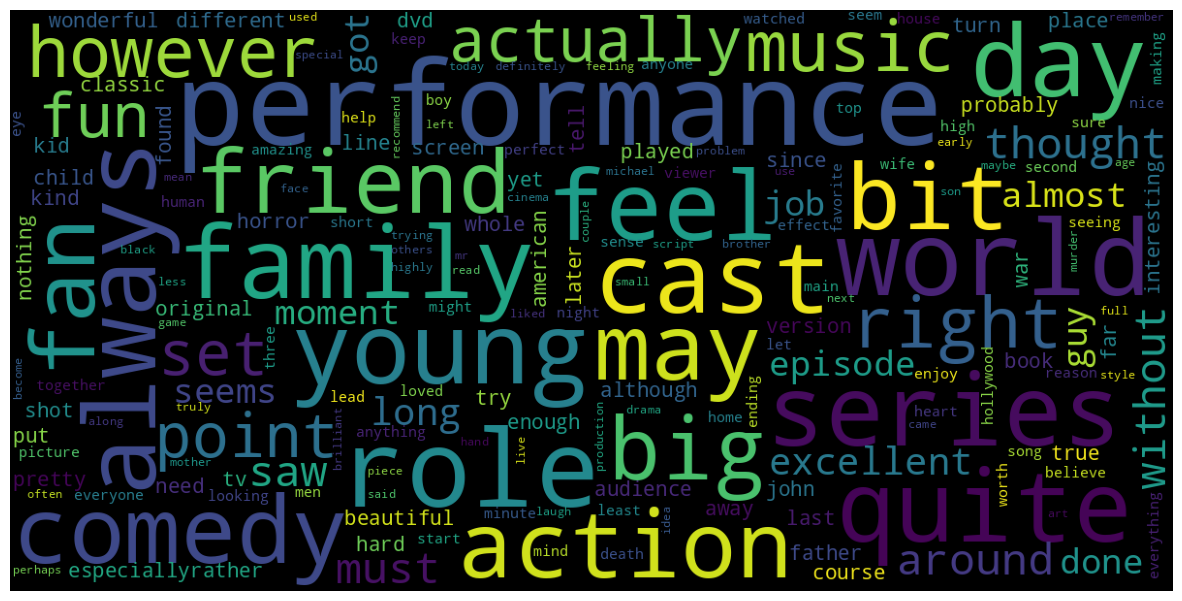

['performance', 'role', 'world', 'young', 'day', 'family', 'series', 'quite', 'cast', 'always', 'feel', 'comedy', 'action', 'may', 'bit', 'friend', 'big', 'fan', 'right', 'music', 'however', 'actually', 'point', 'set', 'fun', 'thought', 'must', 'saw', 'around', 'without', 'excellent', 'long', 'episode', 'got', 'done', 'seems', 'guy', 'almost', 'job', 'moment', 'especially', 'yet', 'played', 'beautiful', 'last', 'pretty', 'child', 'different', 'since', 'war', 'although', 'interesting', 'horror', 'true', 'american', 'place', 'line', 'enough', 'father', 'original', 'tv', 'book', 'wonderful', 'probably', 'kid', 'dvd', 'put', 'far', 'course', 'away', 'kind', 'rather', 'john', 'turn', 'version', 'nothing', 'screen', 'classic', 'later', 'shot', 'tell', 'whole', 'found', 'try', 'audience', 'hard', 'need', 'together', 'sure', 'start', 'making', 'help', 'might', 'ending', 'boy', 'keep', 'perfect', 'everyone', 'wife', 'anyone']
,Filtered Negative


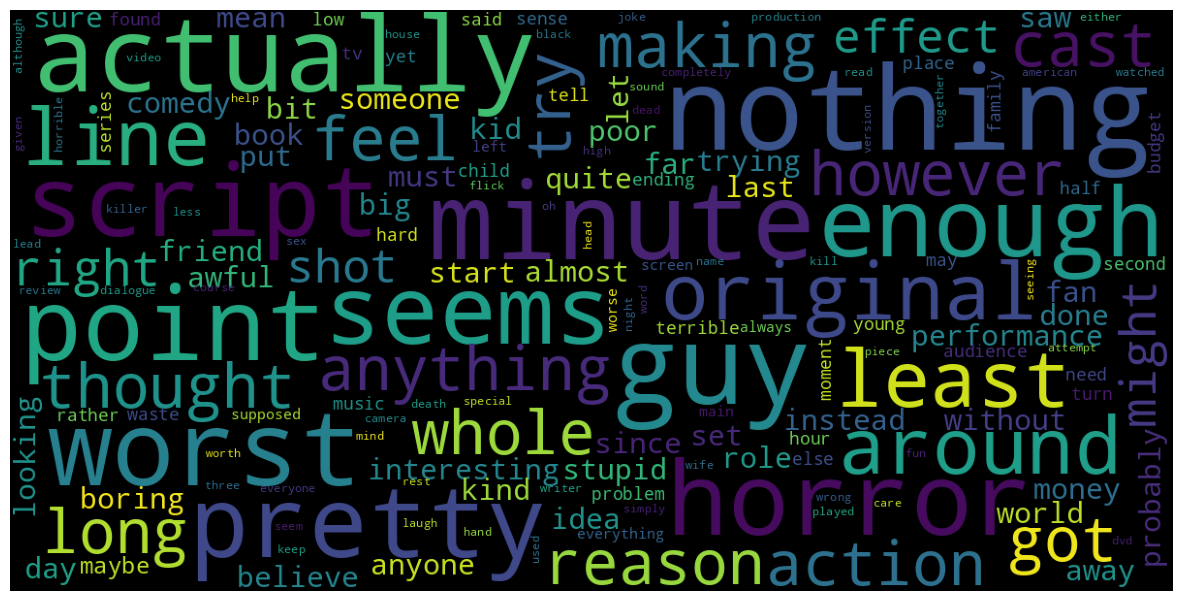

['nothing', 'guy', 'minute', 'worst', 'actually', 'point', 'horror', 'script', 'pretty', 'enough', 'seems', 'original', 'least', 'around', 'line', 'anything', 'got', 'thought', 'try', 'reason', 'whole', 'feel', 'long', 'making', 'however', 'action', 'cast', 'right', 'might', 'effect', 'shot', 'interesting', 'comedy', 'idea', 'day', 'kid', 'start', 'money', 'role', 'big', 'far', 'quite', 'kind', 'let', 'almost', 'fan', 'without', 'must', 'awful', 'performance', 'set', 'done', 'book', 'someone', 'mean', 'poor', 'away', 'boring', 'believe', 'saw', 'stupid', 'probably', 'instead', 'anyone', 'trying', 'sure', 'last', 'bit', 'friend', 'put', 'world', 'since', 'looking', 'maybe', 'terrible', 'rather', 'may', 'hard', 'problem', 'waste', 'tv', 'need', 'music', 'half', 'hour', 'audience', 'place', 'young', 'sense', 'turn', 'tell', 'child', 'series', 'said', 'found', 'family', 'budget', 'else', 'yet', 'moment']


In [35]:
# Let's visualize the words using a wordcloud
stopwords = set(STOPWORDS)

def show_wordcloud(data: [dict], title = None):
    wordcloud = WordCloud(
        background_color='black',
        stopwords=stopwords,
        max_words=200,
        max_font_size=40, 
        scale=3,
        random_state=1 # chosen at random by flipping a coin; it was heads
).generate_from_frequencies(data)
    # 3. Your existing plotting code remains the same:
    fig = plt.figure(1, figsize=(15, 15))
    plt.axis('off')
    if title: 
        fig.suptitle(title, fontsize=20)
        fig.subplots_adjust(top=2.3)
    
    plt.imshow(wordcloud)
    plt.show()

#print("Positive")
#show_wordcloud(pos_wordcloud)
#print("Negative")
#show_wordcloud(neg_wordcloud)

common_pos_words = list(pos_wordcloud.keys())[:100]
common_neg_words = list(neg_wordcloud.keys())[:100]
common_neutral_words = [word for word in common_pos_words if word in common_neg_words]
filtered_pos_wordcloud = {k: v for k, v in pos_wordcloud.items() if k not in common_neutral_words}
filtered_neg_wordcloud = {k: v for k, v in neg_wordcloud.items() if k not in common_neutral_words}
#print(common_neutral_words)

print("Filtered Positive")
show_wordcloud(filtered_pos_wordcloud)
print(list(filtered_pos_wordcloud.keys())[:100])
print("Filtered Negative")
show_wordcloud(filtered_neg_wordcloud)
print(list(filtered_neg_wordcloud.keys())[:100])

#print(clean_train_reviews[0])
#print(clean_train_bigram_reviews[0])

def flatten_bigram(bigram_list):
    big_string = ""
    #iterate over bigrams
    for bigram in bigram_list:
        word1, word2 = bigram.split() #convert bigram from string with spaces to combined, spaceless string
        big_string = big_string + word1 + word2 + " "#combine all spaceless strings  into one string
    return big_string
combined_reviews = [flatten_bigram(x) for x in clean_train_bigram_reviews]
print(combined_reviews[0])

show_wordcloud(combined_reviews[:10])

In [36]:
# Can you make separate word clouds for positive vs. negative reviews?  Do you see any of your top 10 in the word clouds?
#cleaned_pos_reviews = [ review_to_words(review) for review in pos_reviews ]
#cleaned_neg_reviews = [ review_to_words(review) for review in neg_reviews ]
#print(cleaned_pos_reviews[0])

#show_wordcloud(cleaned_pos_reviews)
# your code here

In [37]:
#show_wordcloud(cleaned_neg_reviews)

In [38]:
# Random Forest Classifier Overview
#
# Improved performance variant of Decision Tree Learning, a supervised learning algorithm
#
# https://en.wikipedia.org/wiki/Decision_tree_learning#/media/File:Decision_Tree.jpg
#
# Decision trees are ways of taking input, and then moving left or right depending on your input and coming to a final decision, kind of like turn-by-turn instructions.
#
# For example, passenger survival on the Titanic can be predicted (not perfectly!) using features like sex and age.  Deciding which features and values to put where in the tree comes from taking measurements on the training data.
#
# Some features and values are better at splitting the output into the target predictions than others.  For example, wearing brown clothes vs. wearing black clothes is probably not very predictive of whether passengers survived or not, whereas age appears to be more predictive.
# 
# Let's imagine that one of the nodes in the tree is clothing color.  If you put all the data through the node, the two children nodes resulting from black or brown clothes would likely have something like 50% died and 50% survived, that is, clothing color doesn't separate the people into the target categories very well.
#
# On the other hand, for a node like 'age', being a child or adult could have 90/10 split for children surviving and 20/80 split for adults surviving.  This is a better decision to make when predicting survival because there is higher 'purity' in the outcomes - they're more skewed toward a category of interest than a simple 50/50 split.
#
# This ability to differentiate, or selectivity, is called 'information gain' and can be measured mathematically a few ways.

In [39]:
# Get predicitons
def get_preds(test_feat, train_feat, y_test, y_train, model, title='Random Forest'):
    model.fit(train_feat, y_train)
    preds = model.predict(test_feat)
    
    #accuracy = accuracy_score(y_test, y_pred)
    #print("Accuracy:", accuracy)

    fpr, tpr, _ = roc_curve(y_test, preds)
    roc_auc = auc(fpr, tpr)
    print('AUC:', roc_auc)
    
    #F1 doesn't matter because of class balance here
    
    # plot AUC
    plt.plot(fpr, tpr)
    plt.title(title)
    plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.show()
    
    return preds, model

In [40]:
# Area Under the Curve Definition - https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc
#
# How do you measure model performance?  We're dealing with a binary classification (good review vs. bad review), and we want to know how often our model made the right prediction.
#
# True and false positive rates are one way of measuring correctness.
#
# A true positive is when the model predicts category A and the correct label is category A.
# A false positive is when the model predicts category A the correct label is some other category (not category A).

# A true negative is when the model correctly predicts some other category (!A). 
# A false negative is when the model incorrectly predicts some other category (!A).  The true label is A, but the model predicted something else.

# True positive rate (i.e., recall) is true positives / (true positives + false negatives) 
# False positive rate is false positives / (false positives + true negatives)
#
# Better models have a low false positive rate and a high true positive rate.  If they got all true positives and no false positives, they would be at (0,1) in the AUC graph, and the space between the point and the diagonal line would be maximised.  More area means higher performance.
#
# There are other ways of measuring performance.  

In [41]:
len(vocab)
#with open('/tmp/fst.svg', 'w') as f:
#    f.write(t._repr_svg_())

NameError: name 'vocab' is not defined

vectorizer = CountVectorizer(analyzer = "word",   
                             tokenizer = None,    
                             preprocessor = None, 
                             stop_words = None,   
                             max_features = 100000) 

# Now fit and transform using the strings
train_feat = vectorizer.fit_transform(cleaned_training_reviews).toarray()
test_feat = vectorizer.transform(filtered_unigram_test_reviews).toarray()

print(train_feat[0])
print(test_feat[0])

In [46]:
vectorizer = CountVectorizer(analyzer = "word",   
                             tokenizer = None,    
                             preprocessor = None, 
                             stop_words = None,   
                             max_features = 50000)

# Now fit and transform using the strings
train_feat = vectorizer.fit_transform(combined_training_reviews).toarray()
test_feat = vectorizer.transform(combined_test_reviews).toarray()

print(train_feat[0])
print(test_feat[0])

[0 0 0 ... 0 0 0]
,[0 0 0 ... 0 0 0]


start_time = time.time()
preds_rf, model = get_preds(test_feat, train_feat, y_test, y_train,
                  RandomForestClassifier(n_estimators = 100))

end_time = time.time()
print("Elapsed:",end_time-start_time)

 # visualize decision tree from classifier
for i in range(10):
    tree = model.estimators_[i]
    dot_data = export_graphviz(tree,
                            feature_names=vocab,  
                            filled=True,  
                           max_depth=2, 
                           impurity=False, 
                           proportion=True)
    graph = graphviz.Source(dot_data)
    display(graph)

In [47]:
def get_accuracy(preds, labels):
    correct = 0
    assert len(preds) == len(labels)
    for i in range(len(preds)):
        if preds[i] == labels[i]:
            correct += 1
    print("Accuracy: {}".format(correct/len(preds)))

preds = preds_rf.tolist()
labels = y_test.tolist()

get_accuracy(preds, labels)

NameError: name 'preds_rf' is not defined

In [ ]:
print(preds_rf[0]) #first prediction for test item - model predicted positive sentiment
print(test_feat[0]) #first test review
print(cleaned_test_reviews[0])
print(type(y_test))
print(y_test.iloc[0])

In [ ]:
# multilayer perceptron classier
# Importing necessary libraries
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

AUC: 0.8696


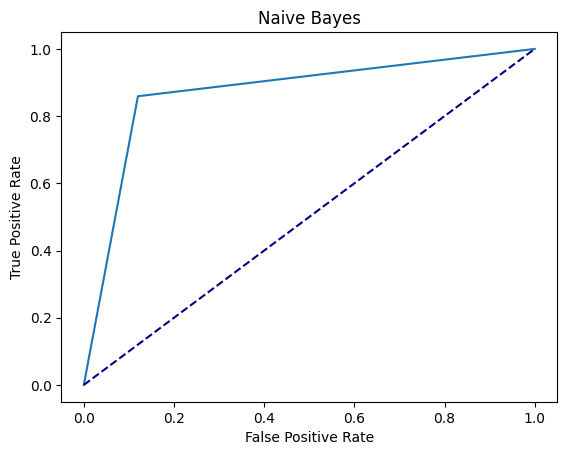

Elapsed: 6.651195526123047


In [53]:
start_time = time.time()
preds_nb, model = get_preds(test_feat, train_feat, 
                  y_test, y_train, 
                  MultinomialNB(), title='Naive Bayes')
end_time = time.time()
print("Elapsed:",end_time-start_time)

In [ ]:
# Are bigrams better or worse features compared to Bag of Words? Make a prediction.
# https://www.pythonprogramming.in/use-sklearn-countvectorize-vocabulary-specification-with-bigrams.html

# your code here

# Is the performance better or worse?

# Why do you think that is?

In [ ]:
# Naive Bayes assumes independence of features, which is not always the case (rarely the case with language)

# Try other model parameters (e.g., change num_estimators for Random Forest model).  Do you think more estimators will improve or harm model performance?

# Find some other models in sci-kit learn.  Are any better than Naive Bayes?



In [ ]:
#Try calculating some other evaluation metrics

# your code here

# Calculate accuracy

# Calculate precision

# Calculate recall

# Calculate F1

In [ ]:
movie_review = "I love Titanic because 1. Leonardo DiCaprio is fine ash 2. it has a ship blowing up!!!"

cleaned_review = review_to_words(movie_review)
review_feat = vectorizer.transform([cleaned_review]).toarray()

print(len(review_feat[0]))
print(type(review_feat))

cleaned_bigram_review = review_to_bigrams(movie_review, string = True)
review_bigram_feat = vectorizer.transform([cleaned_bigram_review]).toarray()

print(len(review_bigram_feat[0]))
print(type(review_bigram_feat))


In [48]:
movie_neg_review = "I hate Titanic because Rose Dewitt Bukater is a stupid person with a stupid name"

cleaned_neg_review = review_to_words(movie_neg_review)
review_neg_feat = vectorizer.transform([cleaned_neg_review]).toarray()

print(len(review_neg_feat[0]))
print(type(review_neg_feat))

50000
,<class 'numpy.ndarray'>


In [49]:
prediction = model.predict(review_feat)
print(prediction)

#bigram_prediction = model.predict(review_bigram_feat)
#print(bigram_prediction)

neg_prediction = model.predict(review_neg_feat)
print(neg_prediction)

NameError: name 'model' is not defined

# Part II: Word2Vec

In [45]:
# Download the punkt tokenizer if necessary
nltk.download('punkt', download_dir='tokenizers')   

# Load the punkt tokenizer
tokenizer = nltk.data.load('tokenizers/punkt/english.pickle')

# Define a function to split a review into parsed sentences
def review_to_sentences( review, tokenizer, remove_stopwords=False ):
    '''
    Split a review into parsed sentences. 
    Returns a list of sentences, where each sentence is a list of words
    '''
    # Remove HTML
    review = BeautifulSoup(review).get_text()
    # Use the NLTK tokenizer to split the paragraph into sentences
    raw_sentences = tokenizer.tokenize(review.strip())
    #
    # Loop over each sentence
    sentences = []
    for raw_sentence in raw_sentences:
        # If a sentence is empty, skip it
        if len(raw_sentence) > 0:
            # Get a list of words
            sentences.append(review_to_words(raw_sentence, string=False, 
                                             remove_stopwords=False))
    return sentences

[nltk_data] Downloading package punkt to tokenizers...
,[nltk_data]   Package punkt is already up-to-date!


LookupError: 
**********************************************************************
  Resource [93mpunkt_tab[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('punkt_tab')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mtokenizers/punkt_tab/english/[0m

  Searched in:
    - '/users/PZS1154/dukki/nltk_data'
    - '/fs/ess/PZS1154/SI_2026/jupyter/nltk_data'
    - '/fs/ess/PZS1154/SI_2026/jupyter/share/nltk_data'
    - '/fs/ess/PZS1154/SI_2026/jupyter/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [ ]:
sentences = []

for review in X_train["review"]:
    sentences += review_to_sentences(review, tokenizer)

for review in unlabeled_train["review"]:
    sentences += review_to_sentences(review, tokenizer)

In [ ]:
# Set parameters
num_features = 300                   
min_word_count = 40                         
num_workers = 4       
context = 10                                                                                      
downsampling = 1e-3

# Initialize and train the model
model = Word2Vec(sentences, workers=num_workers,
                 vector_size=num_features, min_count = min_word_count,
                 window = context, sample = downsampling)

# If you don't plan to train the model any further, calling 
# init_sims will make the model much more memory-efficient.
#model.init_sims(replace=True)
#4mins?

In [ ]:
def makeFeatureVec(words, model, num_features):
    '''Average all of the word vectors in a paragraph'''
    # Pre-initialize an empty numpy array (for speed)
    featureVec = np.zeros((num_features,),dtype="float32")
    nwords = 0
    # ICreate a set of words on voc 
    index2word_set = set(model.wv.index2word)
    # Add feature vectors if they are inside model vocabulary
    for word in words:
        if word in index2word_set: 
            nwords = nwords + 1
            featureVec = np.add(featureVec,model[word])
    # Get averages
    featureVec = np.divide(featureVec,nwords)
    return featureVec


def getAvgFeatureVecs(reviews, model, num_features):
    '''
    Given a set of reviews (each one a list of words), calculate 
    the average feature vector for each one and return a 2D numpy array 
    '''
    # Initialize a counter
    counter = 0
    # Preallocate a 2D numpy array, for speed
    reviewFeatureVecs = np.zeros((len(reviews),num_features),dtype="float32")
    # Loop through the reviews
    for review in reviews:
        reviewFeatureVecs[counter] = makeFeatureVec(review, model,
                                                   num_features)
        counter = counter + 1
    return reviewFeatureVecs

In [ ]:
# Calculate average feature vectors for training and testing sets,

clean_train_reviews = [review_to_words(review, string=False, remove_stopwords=True) for review in X_train.review]

trainDataVecs = getAvgFeatureVecs(clean_train_reviews, model, num_features)

clean_test_reviews = [review_to_words(review, string=False, remove_stopwords=True) for review in X_test.review]

testDataVecs = getAvgFeatureVecs(clean_test_reviews, model, num_features)

In [ ]:
# Get Results
preds_rf1 = get_preds(testDataVecs, trainDataVecs, 
                      y_test, y_train, 
                      RandomForestClassifier(n_estimators = 100))

In [ ]:
# Use Gaussian NB because Multinomial doesn't work with negative feature values
preds_nb1 = get_preds(testDataVecs, trainDataVecs, 
                      y_test, y_train, 
                      GaussianNB(), title='Naive Bayes')

## Tf-Idf

This is short for term frequency-inverse document frequency. 

Term frequency (the same as bag of words):  $$\text{Tf} = \frac{\text{number of times term appears in document}}{\text{total number of words in document}}$$

Inverse document frequency measures how rare a term is across all documents (the higher the value, the rarer the word): $$\text{Idf} = \ln\left(\frac{\text{total number of documents}}{\text{number of documents with term in them}}\right)$$

We combine these two to get Tf-Idf as follows:
 $$\text{Tf-idf} = \text{Tf} \times \text{Idf}$$

 https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html
 

In [ ]:
# TFIDF train set
tfidf_transformer = TfidfTransformer().fit(train_feat)
train_tfidf = tfidf_transformer.transform(train_feat)

# apply tfidf to test set
test_tfidf = tfidf_transformer.transform(test_feat)

In [ ]:
# Get Results
preds_rf2 = get_preds(test_tfidf, train_tfidf, 
                  y_test, y_train, 
                  RandomForestClassifier(n_estimators = 100))

In [ ]:
preds_nb2 = get_preds(test_tfidf, train_tfidf, 
                  y_test, y_train, 
                  MultinomialNB(), title='Naive Bayes')

In [51]:
model = mlp_classifier

NameError: name 'mlp_classifier' is not defined

In [57]:
!pip install flask flask-cors pyngrok

from flask import Flask, request, jsonify
from flask_cors import CORS
from pyngrok import ngrok

,Requirement already satisfied: flask-cors in /fs/ess/PZS1154/SI_2026/jupyter/lib/python3.9/site-packages (6.0.5)
,Requirement already satisfied: pyngrok in /fs/ess/PZS1154/SI_2026/jupyter/lib/python3.9/site-packages (8.1.2)
,Requirement already satisfied: blinker>=1.9.0 in /fs/ess/PZS1154/SI_2026/jupyter/lib/python3.9/site-packages (from flask) (1.9.0)
,Requirement already satisfied: click>=8.1.3 in /fs/ess/PZS1154/SI_2026/jupyter/lib/python3.9/site-packages (from flask) (8.1.8)
,Requirement already satisfied: importlib-metadata>=3.6.0 in /fs/ess/PZS1154/SI_2026/jupyter/lib/python3.9/site-packages (from flask) (8.7.1)
,Requirement already satisfied: itsdangerous>=2.2.0 in /fs/ess/PZS1154/SI_2026/jupyter/lib/python3.9/site-packages (from flask) (2.2.0)
,Requirement already satisfied: jinja2>=3.1.2 in /fs/ess/PZS1154/SI_2026/jupyter/lib/python3.9/site-packages (from flask) (3.1.6)
,Requirement already satisfied: markupsafe>=2.1.1 in /fs/ess/PZS1154/SI_2026/jupyter/lib/python3.9/site-pac

In [ ]:
from flask import Flask, jsonify, request
from flask_cors import CORS
from pyngrok import ngrok

app = Flask(__name__)
CORS(app)  # Allows your Expo Snack to bypass security lines


@app.route("/predict", methods=["POST"])
def predict():
    # 1. Safely grab the data sent from the Expo Snack app
    data = request.get_json(silent=True)

    if not data:
        print("⚠️ Warning: Received a request with no JSON data.")
        return jsonify({"sentiment": "Error: No data received"}), 400

    user_review = data.get("review", "")
    print(f"📥 Received Review from App: '{user_review}'")

    try:
        # 2. Convert the text into numbers using your trained vectorizer
        # (Make sure 'vectorizer' matches the variable name you used during training!)
        cleaned_review = review_to_words(user_review)
        review_feat = vectorizer.transform([user_review]).toarray()

        # 3. Pass those numbers into your trained AI model
        # (Make sure 'model' matches the variable name of your trained model!)
        raw_prediction = model.predict(review_feat)

        # 4. Turn the model's output (0, 1, 'pos', etc.) into a clean string for the app
        # Change these conditions if your model outputs something different!
        if raw_prediction[0] == 1:
            sentiment_result = "Positive"
        else:
            sentiment_result = "Negative"

        print(f" Model Output: {raw_prediction} -> Sent back: {sentiment_result}")

    except Exception as e:
        print(f" Error during prediction: {e}")
        sentiment_result = f"Python Error: {str(e)}"

    # 5. Send the sentiment back to Expo Snack
    return jsonify({"sentiment": sentiment_result})


# --- SERVER RESET & STARTUP ---
# Clean up any old hidden tunnels so they don't block the port
try:
    ngrok.kill()
except:
    pass

# Authenticate with your token
ngrok.set_auth_token("3F0MJVFQEfxFToWr8nuNqF7ysN1_3FHUinnoKm1BJxahvfTJM")

# Open the gateway tunnel
public_url = ngrok.connect(5000)
print("\n COPY THIS LINK FOR EXPO SNACK:\n", public_url.public_url)

# Run the live Flask server
app.run(port=5000)


, COPY THIS LINK FOR EXPO SNACK:
, https://expectant-boat-contents.ngrok-free.dev
, * Serving Flask app '__main__'
, * Debug mode: off


, * Running on http://127.0.0.1:5000
,Press CTRL+C to quit
,127.0.0.1 - - [12/Jun/2026 15:13:57] "POST /predict HTTP/1.1" 200 -


📥 Received Review from App: 'This movie sucks'
, Model Output: [0] -> Sent back: Negative


127.0.0.1 - - [12/Jun/2026 15:14:57] "POST /predict HTTP/1.1" 200 -


📥 Received Review from App: 'This movie is really interesting in how bad it is'
, Model Output: [0] -> Sent back: Negative


127.0.0.1 - - [12/Jun/2026 15:15:08] "POST /predict HTTP/1.1" 200 -


... (91 outputs left out)

127.0.0.1 - - [12/Jun/2026 15:21:28] "POST /predict HTTP/1.1" 200 -


📥 Received Review from App: 'Although this was entertaining in some parts, overall the movie was disappointment
,'
, Model Output: [0] -> Sent back: Negative


127.0.0.1 - - [12/Jun/2026 15:21:28] "POST /predict HTTP/1.1" 200 -


📥 Received Review from App: 'Although this was entertaining in some parts, overall the movie was disappointment
,'
, Model Output: [0] -> Sent back: Negative
